# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Shifa Batool
- **Student ID:** 023-24-0095
- **Section:** D
- **GitHub:** https://github.com/shifabatool
- **Kaggle:** https://www.kaggle.com/shifabaloch
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/code/basmalaawad/telco-customer-churn-dataset

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)
df = pd.read_csv(
    "/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)
print("Dataset Shape:", df.shape)
df.head()
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Handle missing values
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)
# Drop customerID
df.drop("customerID", axis=1, inplace=True)
# Map Churn to 0 and 1
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})
print("Missing Values:")
print(df.isnull().sum().sum())

df.head()

Dataset Shape: (7043, 21)
Missing Values:
0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [46]:
# One-hot encode
df = pd.get_dummies(
    df,
    drop_first=True
)

X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features:", X.shape)
print("Target:", y.shape)
#define X and y, train_test_split(..., stratify=y)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

#Feature scaling
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)


Features: (7043, 30)
Target: (7043,)
Training Shape: (5634, 30)
Testing Shape: (1409, 30)


## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [47]:
# YOUR CODE HERE — unscaled linear SVM
svm_raw = SVC(
    kernel="linear",
    random_state=42
)

start = time.time()
svm_raw.fit(X_train, y_train)
raw_time = time.time() - start
y_pred_raw = svm_raw.predict(X_test)
raw_accuracy = accuracy_score(y_test, y_pred_raw)
raw_precision = precision_score(y_test, y_pred_raw)
raw_recall = recall_score(y_test, y_pred_raw)
raw_f1 = f1_score(y_test, y_pred_raw)

print("Unscaled Linear SVM")
print("Accuracy:", raw_accuracy)
print("Precision:", raw_precision)
print("Recall:", raw_recall)
print("F1 Score:", raw_f1)
print("Training Time:", raw_time)

Unscaled Linear SVM
Accuracy: 0.7906316536550745
Precision: 0.6639004149377593
Recall: 0.42780748663101603
F1 Score: 0.5203252032520326
Training Time: 369.69177746772766


In [48]:
# YOUR CODE HERE — scaled linear SVM
svm_scaled = SVC(
    kernel="linear",
    random_state=42
)
start = time.time()
svm_scaled.fit(X_train_s, y_train)
scaled_time = time.time() - start
y_pred_scaled = svm_scaled.predict(X_test_s)
scaled_accuracy = accuracy_score(
    y_test,
    y_pred_scaled
)
scaled_f1 = f1_score(
    y_test,
    y_pred_scaled
)
print("Scaled Linear SVM")
print("Accuracy:", scaled_accuracy)
print("F1 Score:", scaled_f1)
print("Training Time:", scaled_time)

Scaled Linear SVM
Accuracy: 0.7892122072391767
F1 Score: 0.5714285714285714
Training Time: 0.8863320350646973


In [49]:
#Comparison Table
scaling_results = pd.DataFrame({
    "Model": ["Unscaled Linear SVM", "Scaled Linear SVM"],
    "Accuracy": [raw_accuracy, scaled_accuracy],
    "F1 Score": [raw_f1, scaled_f1],
    "Training Time": [raw_time, scaled_time]
})

scaling_results

,Model,Accuracy,F1 Score,Training Time
0,Unscaled Linear SVM,0.790632,0.520325,369.691777
1,Scaled Linear SVM,0.789212,0.571429,0.886332


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

**Answer:**
The unscaled and scaled models may produce different accuracy and F1-scores because feature magnitudes affect the SVM decision boundary. Scaling gives features a comparable range and may improve convergence and training efficiency. The exact difference is determined by the experiment.

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

**Answer:**
An SVM calculates the margin using distances between data points and the decision boundary. Features with large numerical values can dominate these distances. Scaling makes features comparable and allows the SVM to learn a more balanced decision boundary.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

**Answer:**
I will use the scaled version because SVM is sensitive to feature magnitudes. StandardScaler helps ensure that features contribute more fairly to the distance and margin calculations.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [50]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
#train 3 SVM models
kernels = ["linear", "rbf", "poly"]

kernel_models = {}

kernel_results = []

for kernel in kernels:

    model = SVC(
        kernel=kernel,
        random_state=42
    )

    start = time.time()

    model.fit(X_train_s, y_train)

    training_time = time.time() - start

    y_pred = model.predict(X_test_s)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    support_vectors = model.support_.shape[0]

    kernel_models[kernel] = model

    kernel_results.append({
        "Kernel": kernel,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Support Vectors": support_vectors,
        "Training Time": training_time
    })

kernel_results


[{'Kernel': 'linear',
  'Accuracy': 0.7892122072391767,
  'Precision': 0.6206896551724138,
  'Recall': 0.5294117647058824,
  'F1 Score': 0.5714285714285714,
  'Support Vectors': 2569,
  'Training Time': 0.8891537189483643},
 {'Kernel': 'rbf',
  'Accuracy': 0.7927608232789212,
  'Precision': 0.6443661971830986,
  'Recall': 0.4893048128342246,
  'F1 Score': 0.5562310030395137,
  'Support Vectors': 2661,
  'Training Time': 0.7124929428100586},
 {'Kernel': 'poly',
  'Accuracy': 0.7892122072391767,
  'Precision': 0.6420664206642066,
  'Recall': 0.46524064171123,
  'F1 Score': 0.5395348837209303,
  'Support Vectors': 2739,
  'Training Time': 0.6224117279052734}]

In [51]:
# YOUR CODE HERE — comparison table
kernel_df = pd.DataFrame(kernel_results)

kernel_df

,Kernel,Accuracy,Precision,Recall,F1 Score,Support Vectors,Training Time
0,linear,0.789212,0.620690,0.529412,0.571429,2569,0.889154
1,rbf,0.792761,0.644366,0.489305,0.556231,2661,0.712493
2,poly,0.789212,0.642066,0.465241,0.539535,2739,0.622412


In [52]:
#find the best kernel
best_kernel = kernel_df.loc[
    kernel_df["F1 Score"].idxmax(),
    "Kernel"
]

best_model = kernel_models[best_kernel]

print("Best Kernel:", best_kernel)

Best Kernel: linear


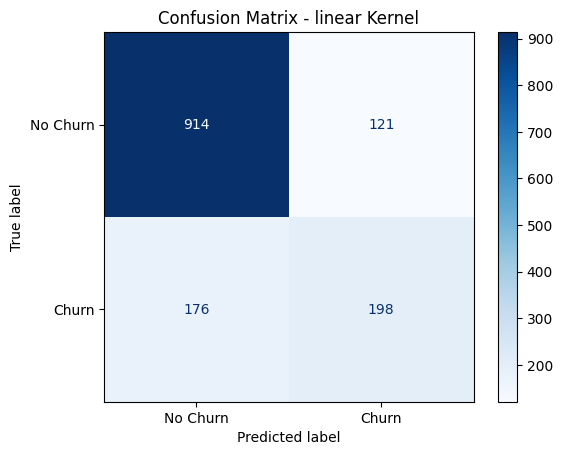

In [53]:
# YOUR CODE HERE — confusion matrix for the best kernel
y_pred_best = best_model.predict(X_test_s)

cm = confusion_matrix(
    y_test,
    y_pred_best
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
).plot(cmap="Blues")

plt.title(f"Confusion Matrix - {best_kernel} Kernel")
plt.show()

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

**Answer:**
The linear kernel produced the best F1-score of approximately 0.5714. This is not surprising because the Telco dataset may contain relationships that can be represented reasonably well using a linear decision boundary. A more complex kernel does not always provide better performance.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

**Answer**
The polynomial kernel used the most support vectors, with 2739 support vectors. A high support-vector count suggests that many training samples influence the decision boundary. However, the count alone does not prove that the boundary is more complex.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

**Answer**
I would carry forward the RBF kernel for Part 4 because the lab specifically requires tuning an RBF SVM. Its test F1-score was approximately 0.5562, while the linear kernel achieved 0.5714. The RBF kernel still provides flexibility to learn nonlinear relationships, and GridSearchCV will help determine whether tuning improves its performance.

---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [54]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_s)

print(
    "Explained Variance Ratio:",
    pca.explained_variance_ratio_
)

print(
    "Total Explained Variance:",
    pca.explained_variance_ratio_.sum()
)


Explained Variance Ratio: [0.33246151 0.11980321]
Total Explained Variance: 0.45226472427671316


In [55]:
#testing
X_test_pca = pca.transform(X_test_s)

In [56]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
C_values = [0.01, 1, 100]

pca_models = {}

for C in C_values:

    model = SVC(
        kernel="rbf",
        C=C,
        random_state=42
    )

    model.fit(
        X_train_pca,
        y_train
    )

    pca_models[C] = model

    print(
        "C =", C,
        "| Support Vectors =",
        model.support_.shape[0]
    )

C = 0.01 | Support Vectors = 2997
C = 1 | Support Vectors = 2659
C = 100 | Support Vectors = 2631


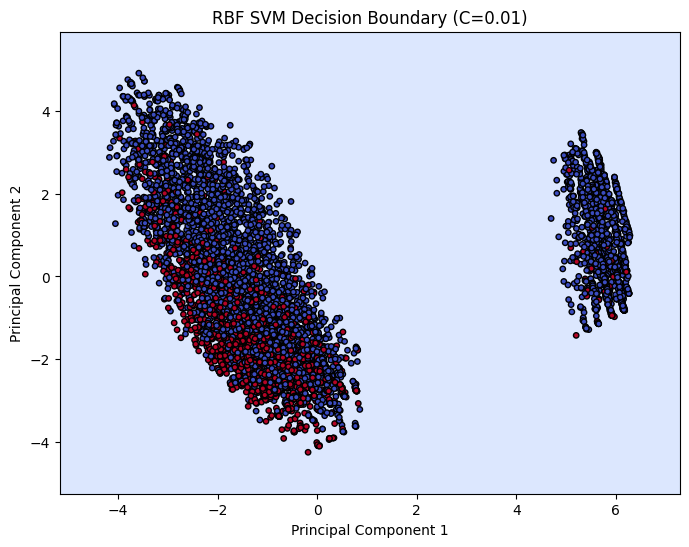

C=0.01, Support Vectors: 2997


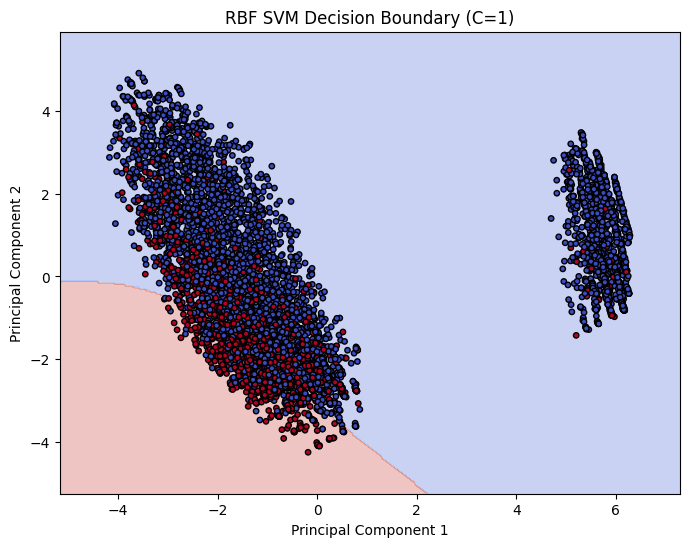

C=1, Support Vectors: 2659


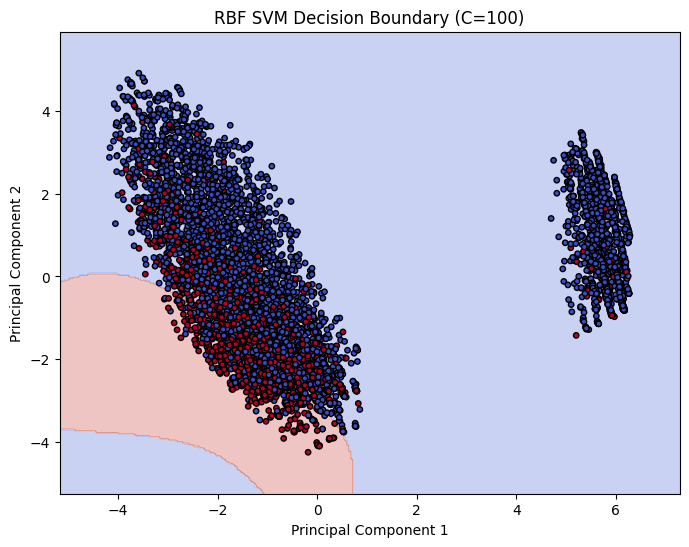

C=100, Support Vectors: 2631


In [57]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
# Create mesh grid
x_min = X_train_pca[:, 0].min() - 1
x_max = X_train_pca[:, 0].max() + 1

y_min = X_train_pca[:, 1].min() - 1
y_max = X_train_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Plot for each C
for C in C_values:

    model = pca_models[C]

    Z = model.predict(grid)

    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(
        xx,
        yy,
        Z,
        alpha=0.3,
        cmap="coolwarm"
    )

    plt.scatter(
        X_train_pca[:, 0],
        X_train_pca[:, 1],
        c=y_train,
        cmap="coolwarm",
        edgecolors="k",
        s=15
    )

    plt.title(
        f"RBF SVM Decision Boundary (C={C})"
    )

    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")

    plt.show()

    print(
        f"C={C}, Support Vectors:",
        model.support_.shape[0]
    )

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

**Answer**
As C increases, the SVM places greater importance on correctly classifying training samples. The decision boundary may become more irregular as the model attempts to reduce classification errors.

(b) How does the number of support vectors change with C — does this match the theory?

**Answer**
The number of support vectors can change as C increases. A smaller C generally allows more margin violations, while a larger C penalizes them more strongly. The exact support-vector count depends on the dataset and the learned boundary.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

**Answer:**
A small C such as 0.01 may underfit because the boundary can be too simple to capture the data patterns. A large C such as 100 may overfit if the boundary becomes highly irregular and follows individual training points.

The actual decision-boundary plots should be used to confirm this.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

**Answer**
The original dataset contains many features. PCA reduces the data to only two principal components, which may discard important information. Therefore, the 2-D decision boundary is not the same as the original high-dimensional SVM boundary and may give a misleading impression of the model's actual performance.

---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [58]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
param_grid = {
    "C": [0.1, 1, 10],
    "gamma": ["scale", 0.01, 0.1, 1]
}
#Run gridsearchCV
gs = GridSearchCV(
    estimator=SVC(
        kernel="rbf",
        random_state=42
    ),

    param_grid=param_grid,

    cv=5,

    scoring="f1",

    n_jobs=-1,

    verbose=1
)
gs.fit(
    X_train_s,
    y_train
)
print("Best Parameters:", gs.best_params_)

print("Best CV F1 Score:", gs.best_score_)
#extract grid search results
results = pd.DataFrame(
    gs.cv_results_
)

results[
    [
        "param_C",
        "param_gamma",
        "mean_test_score",
        "std_test_score"
    ]
]

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters: {'C': 10, 'gamma': 0.01}
Best CV F1 Score: 0.5852822456612709


,param_C,param_gamma,mean_test_score,std_test_score
0,0.1,scale,0.526832,0.031259
1,0.1,0.01,0.541689,0.031503
2,0.1,0.1,0.463951,0.036626
3,0.1,1,0.000000,0.000000
4,1.0,scale,0.576485,0.029308
5,1.0,0.01,0.565038,0.033742
6,1.0,0.1,0.573405,0.026669
7,1.0,1,0.326124,0.025887
8,10.0,scale,0.574785,0.020266
9,10.0,0.01,0.585282,0.025348


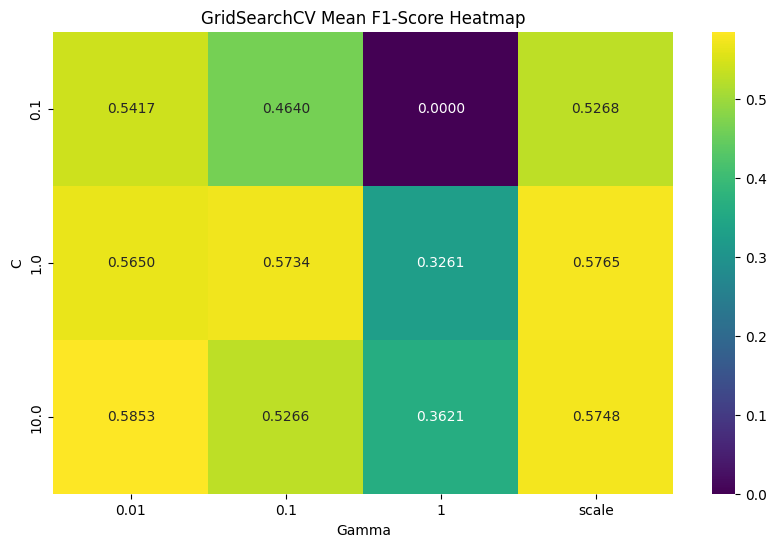

In [59]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
heatmap_data = results.pivot(
    index="param_C",
    columns="param_gamma",
    values="mean_test_score"
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".4f",
    cmap="viridis"
)

plt.title("GridSearchCV Mean F1-Score Heatmap")

plt.xlabel("Gamma")
plt.ylabel("C")

plt.show()

In [60]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
best_svm = gs.best_estimator_

y_pred_tuned = best_svm.predict(
    X_test_s
)

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred_tuned)
)

print(
    "Precision:",
    precision_score(y_test, y_pred_tuned)
)

print(
    "Recall:",
    recall_score(y_test, y_pred_tuned)
)

print(
    "F1 Score:",
    f1_score(y_test, y_pred_tuned)
)

print(
    "\nClassification Report:\n"
)

print(
    classification_report(
        y_test,
        y_pred_tuned
    )
)

Accuracy: 0.7885024840312278
Precision: 0.62751677852349
Recall: 0.5
F1 Score: 0.5565476190476191

Classification Report:

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.63      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



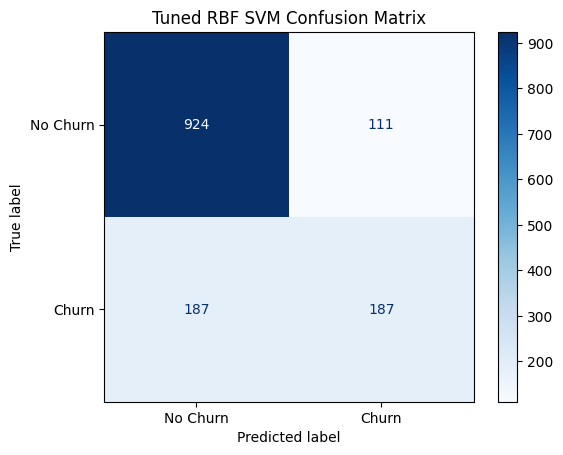

In [61]:
#confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred_tuned
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
).plot(cmap="Blues")

plt.title("Tuned RBF SVM Confusion Matrix")

plt.show()

In [62]:
print("Best C:", gs.best_params_["C"])

print("Best Gamma:", gs.best_params_["gamma"])

print("Best CV F1:", gs.best_score_)

Best C: 10
Best Gamma: 0.01
Best CV F1: 0.5852822456612709


**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

**Answer:**
Best C: 10
Best Gamma: 0.01
Best CV F1: 0.5852822456612709

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

**Answer**
If several combinations have similar F1-scores, it indicates that the model is not extremely sensitive to small changes in those hyperparameters within that region. If only one combination performs well, the model may be more sensitive to the selected values.


(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

**Answer**
The cross-validated F1-score represents the average performance across the training folds, while the test F1-score measures performance on unseen data. A large gap may indicate overfitting during model selection or differences between the training and testing distributions.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

**Answer:**
Compare the tuned RBF F1-score with the untuned RBF F1-score from Part 2, which was approximately 0.5562.

Tuning is worthwhile if it produces a meaningful improvement in F1-score or another important business metric.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [63]:
#train both models
best_C = gs.best_params_["C"]

best_gamma = gs.best_params_["gamma"]

svm_default = SVC(
    kernel="rbf",
    C=best_C,
    gamma=best_gamma,
    class_weight=None,
    random_state=42
)

svm_balanced = SVC(
    kernel="rbf",
    C=best_C,
    gamma=best_gamma,
    class_weight="balanced",
    random_state=42
)

svm_default.fit(
    X_train_s,
    y_train
)

svm_balanced.fit(
    X_train_s,
    y_train
)

SVC(C=10, class_weight='balanced', gamma=0.01, random_state=42)

In [64]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
models = {
    "Default": svm_default,
    "Balanced": svm_balanced
}

imbalance_results = []

for name, model in models.items():

    y_pred = model.predict(X_test_s)

    imbalance_results.append({
        "Model": name,

        "Precision": precision_score(
            y_test,
            y_pred
        ),

        "Recall": recall_score(
            y_test,
            y_pred
        ),

        "F1 Score": f1_score(
            y_test,
            y_pred
        )
    })

imbalance_df = pd.DataFrame(
    imbalance_results
)

imbalance_df

,Model,Precision,Recall,F1 Score
0,Default,0.627517,0.500000,0.556548
1,Balanced,0.506969,0.778075,0.613924


Default


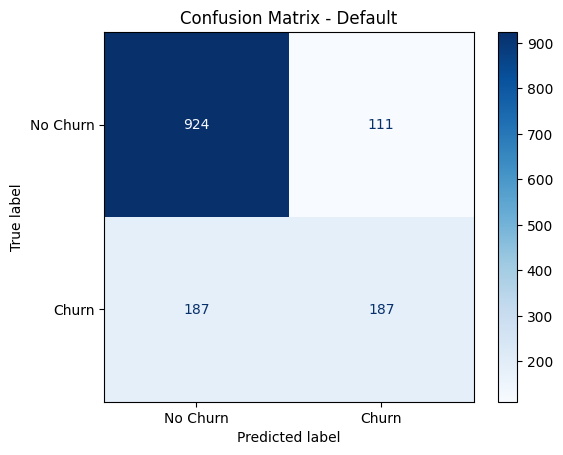

Balanced


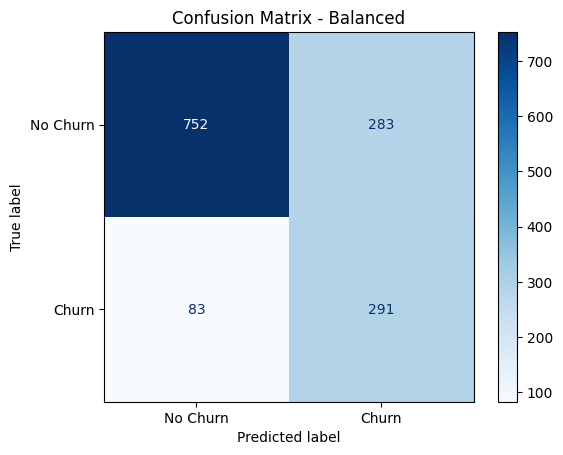

In [65]:
#confusion matrix
for name, model in models.items():

    y_pred = model.predict(X_test_s)

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    print(name)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    ).plot(cmap="Blues")

    plt.title(
        f"Confusion Matrix - {name}"
    )

    plt.show()

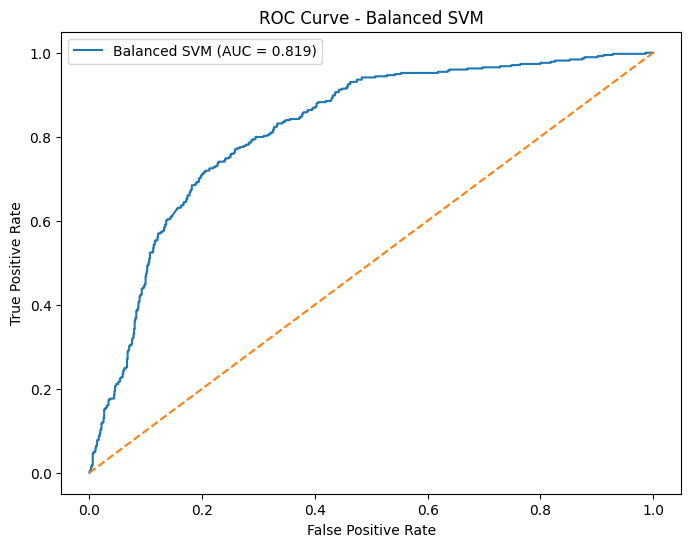

      Model  Precision    Recall  F1 Score
0   Default   0.627517  0.500000  0.556548
1  Balanced   0.506969  0.778075  0.613924


In [66]:
# YOUR CODE HERE — ROC or Precision-Recall curve
probability=True
svm_balanced_prob = SVC(
    kernel="rbf",
    C=best_C,
    gamma=best_gamma,
    class_weight="balanced",
    probability=True,
    random_state=42
)

svm_balanced_prob.fit(
    X_train_s,
    y_train
)

y_prob = svm_balanced_prob.predict_proba(
    X_test_s
)[:, 1]

#plot
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Balanced SVM (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Balanced SVM")

plt.legend()

plt.show()

print(imbalance_df)

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

**Answer:**
When class_weight="balanced" was applied, precision changed from 0.627517 to 0.506969, while recall changed from 0.500000 to 0.778075. This indicates that the balanced model identified a different proportion of actual churners and incorrectly flagged customers.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

**Answer:**
For a telecom company, missing an actual churner may be more costly because the company loses a customer and their future revenue. However, wrongly flagging a loyal customer can also waste retention resources.

I would recommend the balanced model if its higher recall identifies significantly more churners and the additional false positives are manageable. Otherwise, the default model may provide a better business trade-off.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

**Answer**
I enabled probability=True in SVC(). This allows the model to estimate probability-like scores using an additional probability calibration procedure. These scores can be used to construct ROC and Precision-Recall curves.

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [67]:
#import models
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

In [68]:
#train all models
comparison_models = {

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": best_svm
}

In [69]:
#train and evaluate
comparison_results = []

for name, model in comparison_models.items():

    # Fit
    model.fit(
        X_train_s,
        y_train
    )

    # Predict
    y_pred = model.predict(
        X_test_s
    )

    # Metrics
    comparison_results.append({

        "Model": name,

        "Accuracy": accuracy_score(
            y_test,
            y_pred
        ),

        "Precision": precision_score(
            y_test,
            y_pred
        ),

        "Recall": recall_score(
            y_test,
            y_pred
        ),

        "F1 Score": f1_score(
            y_test,
            y_pred
        )
    })

In [70]:
# YOUR CODE HERE — cross-model comparison table
comparison_df = pd.DataFrame(
    comparison_results
)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.740951,0.512535,0.491979,0.502046
1,Random Forest,0.785664,0.621622,0.491979,0.549254
2,Logistic Regression,0.806955,0.658385,0.566845,0.609195
3,KNN,0.747339,0.525281,0.500000,0.512329
4,SVM,0.788502,0.627517,0.500000,0.556548


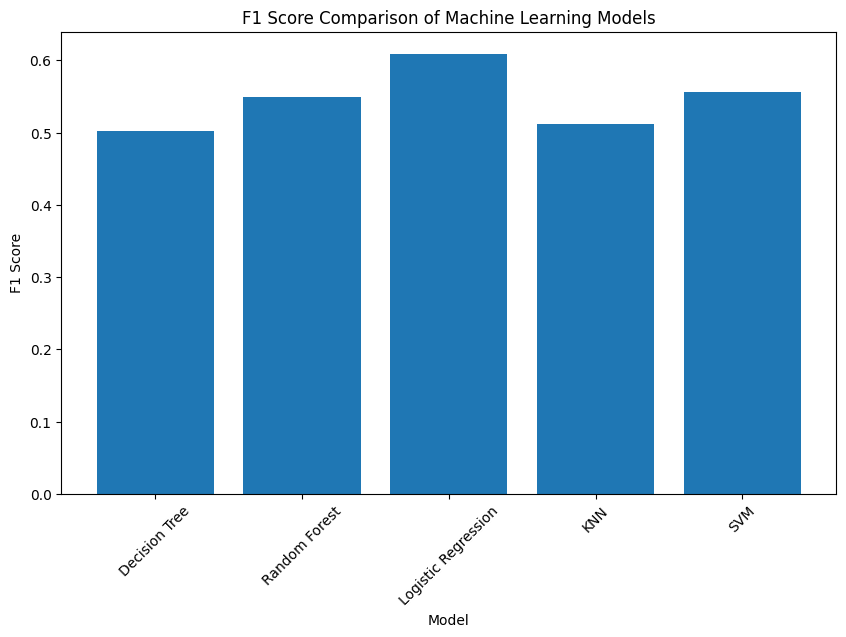

In [71]:
# YOUR CODE HERE — bar chart of F1-score across models
plt.figure(figsize=(10, 6))

plt.bar(
    comparison_df["Model"],
    comparison_df["F1 Score"]
)

plt.xlabel("Model")

plt.ylabel("F1 Score")

plt.title(
    "F1 Score Comparison of Machine Learning Models"
)

plt.xticks(
    rotation=45
)

plt.show()

In [72]:
#for question 1
print(
    "Best F1 Model:",
    comparison_df.loc[
        comparison_df["F1 Score"].idxmax(),
        "Model"
    ]
)

print(
    "Best Recall Model:",
    comparison_df.loc[
        comparison_df["Recall"].idxmax(),
        "Model"
    ]
)

Best F1 Model: Logistic Regression
Best Recall Model: Logistic Regression


**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

**Answer**
The output in above cell  identifies the model with the highest F1-score and the model with the highest recall. These may be different models because F1-score balances precision and recall, whereas recall focuses only on identifying actual churners.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

**Answer**
The answer depends on the measured performance difference. If SVM achieves a substantially higher F1-score or recall than Decision Tree and Random Forest, its additional training cost may be justified. If the improvement is small, a faster tree-based model may be more practical.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

**Answer**
I would recommend the model that provides the best balance between F1-score and recall while maintaining acceptable precision.

For churn prediction, recall is important because the company wants to identify customers who are likely to leave. Precision is also important because retention campaigns have a cost.

The final model should therefore be selected using the actual comparison table rather than accuracy alone.


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [75]:
# YOUR CODE HERE — generate and save svm_predictions.csv
final_model = best_svm

# Predictions
final_predictions = final_model.predict(
    X_test_s
)

# Get decision scores instead of probabilities
final_scores = final_model.decision_function(
    X_test_s
)

# Save predictions
svm_predictions = pd.DataFrame({

    "True_Churn": y_test.values,

    "Predicted_Churn": final_predictions,

    "Predicted_Churn_Score": final_scores
})

svm_predictions.to_csv(
    "svm_predictions.csv",
    index=False
)

svm_predictions.head()

,True_Churn,Predicted_Churn,Predicted_Churn_Score
0,0,0,-1.166942
1,0,1,1.308307
2,0,0,-1.379191
3,0,0,-0.573429
4,0,0,-1.307773


In [76]:
from google.colab import files

files.download(
    "svm_predictions.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Executive Summary**

*In this lab, I implemented Support Vector Machines to predict customer churn using the Telco Customer Churn dataset. I compared linear, RBF, and polynomial kernels and evaluated their performance using accuracy, precision, recall, and F1-score. The linear kernel achieved an F1-score of approximately 0.5714 in the initial kernel comparison, while the RBF kernel achieved approximately 0.5562. I used GridSearchCV with five-fold cross-validation to optimize the RBF kernel's C and gamma parameters. I also investigated the effect of class weighting on the precision-recall trade-off and examined whether identifying more churners justified additional false positives. The final model was selected by comparing its performance with Decision Tree, Random Forest, Logistic Regression, and KNN. One limitation of this analysis is that the model was evaluated on a single train-test split, and its performance may vary on future customer data.*

**Final Reflection**
(a) What was the single most surprising result in this lab?

**Answer**
The most surprising result was that the linear SVM achieved a higher F1-score than the RBF and polynomial kernels in the initial comparison. This demonstrated that a more complex kernel does not always provide better classification performance.

(b) If you had one more hour, what would you try next?

**Answer**
I would try additional feature engineering and different hyperparameter ranges. I would also investigate alternative methods for handling class imbalance, such as SMOTE, and compare their effect on recall and F1-score.